# Քաղաքականություն՝ առնվազն 90% precision

Նպատակը՝ **inhibitor կանխատեսումների մեջ նվազեցնել կեղծ ահազանգերը**։ Training scaffold-CV OOF score-ներով պահանջում ենք առնվազն **90% precision**, հետո այդ պայմանը բավարարող շեմերից ընտրում ենք առավելագույն recall-ը։

Սա ընդհանուր accuracy-ի առավելագույնը չէ։ Բարձր precision-ի դիմաց կարող ենք շատ իրական inhibitor բաց թողնել։ «Non-inhibitor» կանխատեսումը անվտանգ լինելու հաստատում չէ։ 90%-ը training OOF-ի դիտարկված թիրախ է, ոչ ապագա արդյունքի երաշխիք։

Գործարկիր **Run All**։ Test-ը շեմի ընտրության համար չի օգտագործվում։ Այս test set-ն արդեն դիտարկված է, հետևաբար համեմատությունը նոր անկախ վավերացում չէ։

**Պահպանված նախորդ մոդելը․** առկայության դեպքում այս notebook-ը կարդում է `herg_precision_baseline.joblib`-ը՝ նախորդ համեմատությունը պահպանելու համար։ Նոր որոնումը՝ `05_model_improvement.ipynb`-ում։

## 1. Ֆիքսված կանոնը և տվյալները

Ամեն training տողի OOF score-ը ստացել ենք առանց այդ տողի կամ նույն scaffold-ի վրա ուսուցման։ Շեմը ընտրում ենք միայն այդ score-ներով։ Նույն լավագույն recall-ի դեպքում ընտրում ենք ավելի բարձր precision-ը, հետո՝ ավելի բարձր շեմը։ Եթե թիրախն անհասանելի է, կոդը սխալ է վերադարձնում և ինքնուրույն չի թուլացնում պայմանը։

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.modeling import select_f1_threshold, select_precision_threshold
baseline_path = ROOT / "models/herg_precision_baseline.joblib"
path = baseline_path if baseline_path.is_file() else ROOT / "models/herg_model.joblib"
if not path.is_file():
    raise FileNotFoundError("Run make train first.")
a = joblib.load(path)  # Only load your own trusted artifact.
if a.get("threshold_selection", {}).get("criterion") != "precision":
    raise ValueError("Activate the precision policy first; see README.")
data_path = ROOT / "data/raw/herg_karim.csv"
assert sha256(data_path.read_bytes()).hexdigest() == a["dataset_sha256"], "Dataset changed; retrain."
oof = a["oof_predictions"].copy()
test = a["test_predictions"].copy()
assert oof.row_index.is_unique
assert set(oof.row_index) == set(a["train_indices"])
assert set(oof.row_index).isdisjoint(test.row_index)
assert oof.groupby("scaffold").fold.nunique().eq(1).all()
assert set(oof.scaffold).isdisjoint(test.scaffold)
target = a["threshold_selection"]["min_precision"]
selected = select_precision_threshold(oof.label, oof.score, target)
f1_selected = select_f1_threshold(oof.label, oof.score)
assert selected == a["threshold_selection"]
assert selected["threshold"] == a["decision_threshold"]
assert selected["precision"] >= target
np.testing.assert_array_equal(test.threshold_prediction, test.score >= selected["threshold"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
display(pd.Series(selected, name="Selected on training OOF only").to_frame())
display(pd.Series({"Model": a["model_name"], "OOF rows": len(oof), "Test rows": len(test)}, name="Data").to_frame())

,Selected on training OOF only
threshold,0.672021
criterion,precision
min_precision,0.9
source,training_scaffold_oof
precision,0.900596
recall,0.534226
f1,0.670636


,Data
Model,Random forest
OOF rows,10765
Test rows,2680


## 2. Որտե՞ղ է բավարարվում 90% precision-ը

Ձախ գրաֆիկի կանաչ հատվածներում training OOF precision-ը բավարարում է թիրախին։ Դրանք պարտադիր մեկ շարունակական միջակայք չեն․ precision-ը ամեն շեմի հետ պարտադիր չի աճում։ Ուղղահայաց նարնջագույն գիծը ընտրված շեմն է։

Աջ գրաֆիկի կետը ցույց է տալիս այդ շեմի precision–recall զույգը։ Precision-ը բարձրացնելիս recall-ի անկումը բացահայտ երևում է։ Այս լավագույն OOF արդյունքը ընտրության գնահատական է, ոչ անկախ ստուգում․ CV-ն օգտագործվել է նաև մոդելն ընտրելու համար։

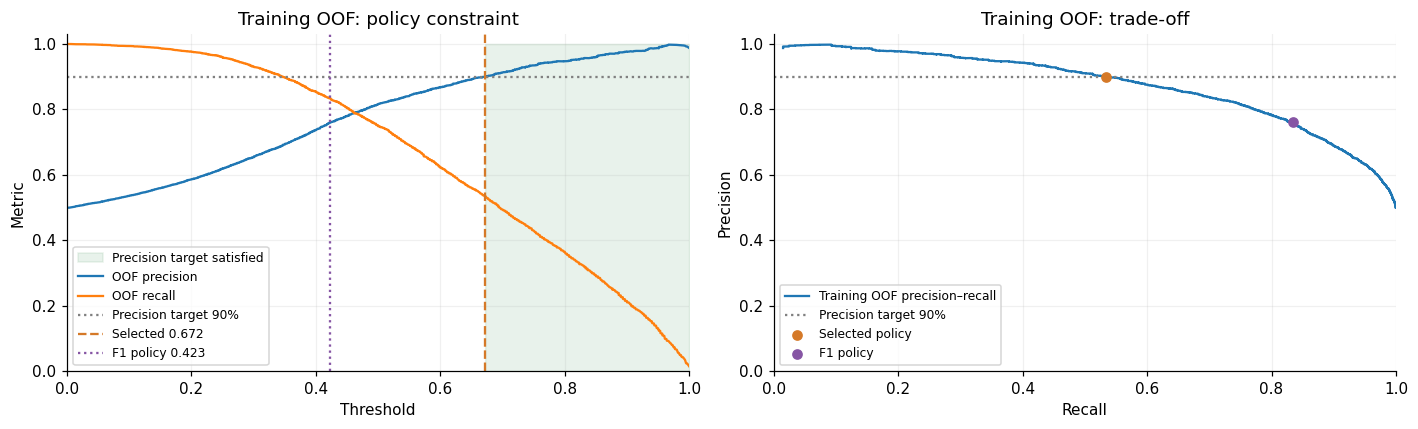

In [2]:
precision, recall, thresholds = precision_recall_curve(oof.label, oof.score)
precision, recall = precision[:-1], recall[:-1]
feasible = precision >= target
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].fill_between(thresholds, 0, 1, where=feasible, color="#6aa879", alpha=0.15, label="Precision target satisfied")
axes[0].plot(thresholds, precision, label="OOF precision")
axes[0].plot(thresholds, recall, label="OOF recall")
axes[0].axhline(target, color="gray", linestyle=":", label=f"Precision target {target:.0%}")
axes[0].axvline(selected["threshold"], color="#d57928", linestyle="--", label=f"Selected {selected['threshold']:.3f}")
axes[0].axvline(f1_selected["threshold"], color="#8655a4", linestyle=":", label=f"F1 policy {f1_selected['threshold']:.3f}")
axes[0].set(xlabel="Threshold", ylabel="Metric", title="Training OOF: policy constraint")
axes[1].step(recall, precision, where="post", label="Training OOF precision–recall")
axes[1].axhline(target, color="gray", linestyle=":", label=f"Precision target {target:.0%}")
axes[1].scatter(selected["recall"], selected["precision"], color="#d57928", zorder=4, label="Selected policy")
axes[1].scatter(f1_selected["recall"], f1_selected["precision"], color="#8655a4", zorder=4, label="F1 policy")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Training OOF: trade-off")
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

## 3. Test համեմատություն՝ երեք քաղաքականություն

Շեմերն արդեն ընտրված են training OOF-ից։ Ստորև test score-ները նույնն են բոլոր երեք տարբերակներում․ փոխվում է միայն որոշման կանոնը։

- **Original classifier** — սկզբնական `predict` արդյունքը։
- **Maximum OOF F1** — նախկին F1 քաղաքականությունը։
- **Precision target** — նոր precision քաղաքականությունը։

90% թիրախը test-ով չենք վերահարմարեցնում։ Եթե test precision-ը լիներ 90%-ից ցածր, դա կարձանագրեինք՝ առանց նոր շեմ որոնելու։ AP-ն ու ROC-AUC-ը նույն score-ների համար չեն փոխվում։

,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
Policy,,,,,,,,
Original classifier,0.8436,0.7675,0.8037,0.8123,1147,191,312,1030
Maximum OOF F1,0.7799,0.8368,0.8073,0.8000,1021,317,219,1123
Precision target,0.9142,0.5797,0.7095,0.7623,1265,73,564,778


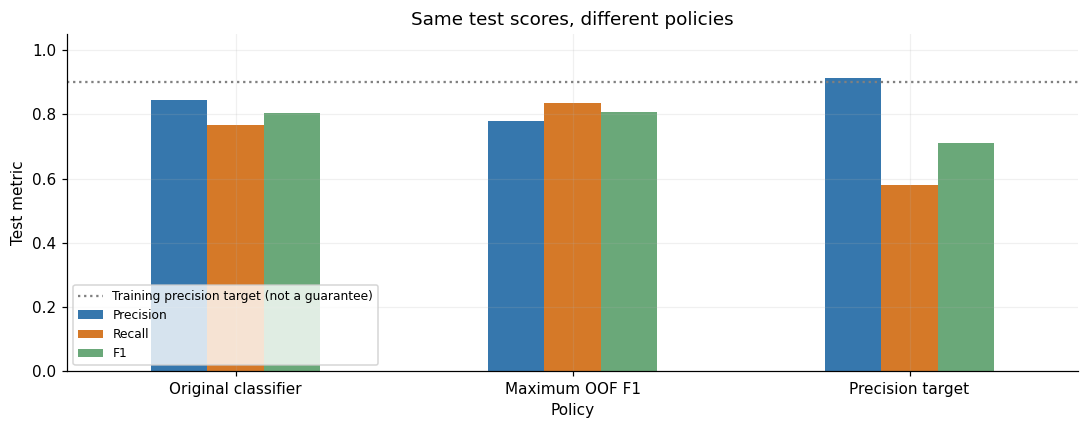

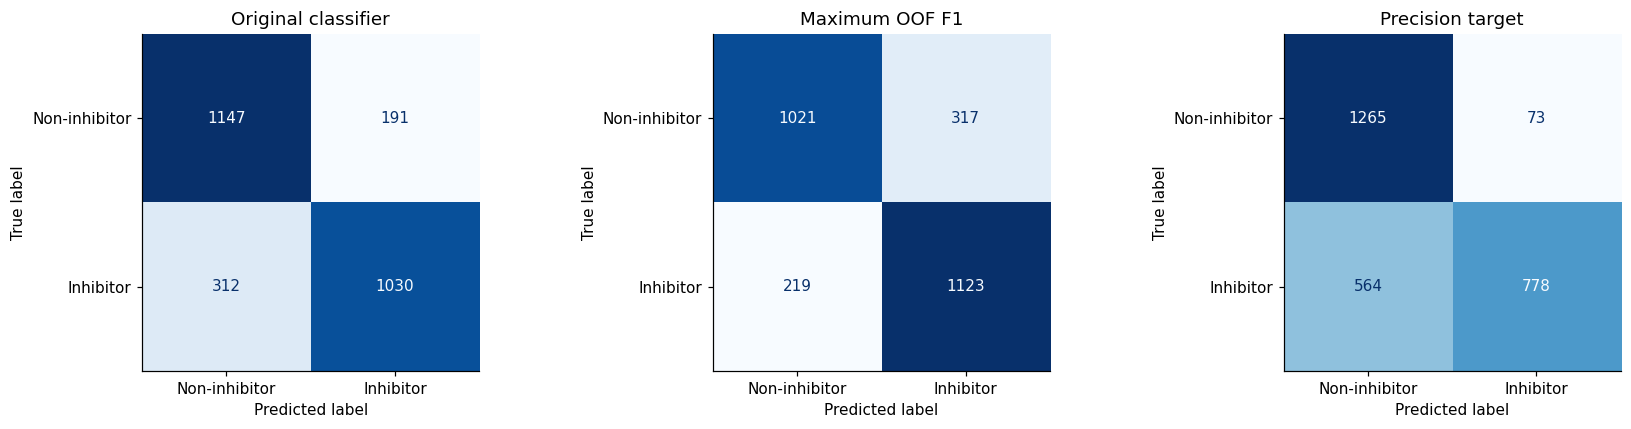

In [3]:
predictions = {
    "Original classifier": test.prediction.to_numpy(),
    "Maximum OOF F1": (test.score.to_numpy() >= f1_selected["threshold"]).astype(int),
    "Precision target": test.threshold_prediction.to_numpy(),
}
rows = []
for name, prediction in predictions.items():
    tn, fp, fn, tp = confusion_matrix(test.label, prediction, labels=[0, 1]).ravel()
    rows.append({"Policy": name,
        "Precision": precision_score(test.label, prediction, zero_division=0),
        "Recall": recall_score(test.label, prediction, zero_division=0),
        "F1": f1_score(test.label, prediction, zero_division=0),
        "Accuracy": accuracy_score(test.label, prediction),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})
comparison = pd.DataFrame(rows).set_index("Policy")
for key in ["Precision", "Recall", "F1"]:
    assert np.isclose(comparison.loc["Precision target", key], a["threshold_test_metrics"][key.lower()])
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
comparison[["Precision", "Recall", "F1"]].plot.bar(ax=ax, color=["#3677ad", "#d57928", "#6aa879"], rot=0)
ax.axhline(target, color="gray", linestyle=":", label="Training precision target (not a guarantee)")
ax.set(ylabel="Test metric", xlabel="Policy", ylim=(0, 1.05), title="Same test scores, different policies")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, prediction) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(test.label, prediction, labels=[0, 1],
        display_labels=["Non-inhibitor", "Inhibitor"], cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
    ax.grid(False)
fig.tight_layout()
plt.show()

## 4. Այս գործարկման գործնական իմաստը

Նոր շեմը մոտ **0.67202** է։ Training OOF precision-ը **90.1%** է, recall-ը՝ **53.4%**։ Test-ում precision-ը **91.4%** է, recall-ը՝ **58.0%**։

Նախկին F1 քաղաքականության համեմատ՝ կեղծ ահազանգերը **317-ից նվազել են 73-ի**, բայց բաց թողնված inhibitor-ները **219-ից աճել են 564-ի**։ Այս քաղաքականության «inhibitor» պատասխաններն ավելի հազվադեպ են սխալ, սակայն շատ իրական inhibitor-ներ չենք հայտնաբերում։

Ավելի բարձր precision-ը չի նշանակում ընդհանուր ավելի լավ մոդել կամ ավելի ճիշտ տվյալներ։ Պիտակները և score-ները նույնն են։ Այս թվերը վերաբերում են պահպանված գործարկմանը։

## 5. Կիրառումն ու սահմանափակումները

Հավելվածը կիրառում է պահված `decision_threshold`-ը և ցույց է տալիս քաղաքականությունն ու test արդյունքները։ Ամբողջ dataset-ով վերաուսուցանված demo մոդելի score-ները կարող են տարբերվել գնահատման մոդելից․ այս արդյունքները չեն երաշխավորում ապագա precision-ը։

Քաղաքականությունը առանց մոդելի վերաուսուցման վերակիրառելու համար՝

```bash
.venv/bin/python -m src.train --reselect-threshold --threshold-policy precision --min-precision 0.9
```

`make train`-ն այժմ լռելյայն ընտրում է այս քաղաքականությունը։ Նախկին F1 տարբերակը հասանելի է `--threshold-policy f1`-ով։